In [12]:
import pandas as pd

df = pd.read_csv(
    "entreprises_IA_Marrakech.csv",
    encoding="utf-8-sig"
)

print("Shape:", df.shape)

display(df.head())

Shape: (503, 11)


,place_id,nom,adresse,telephone,site_web,google_maps,categorie,note,nombre_avis,latitude,longitude
0,ChIJnUvH9aztrw0RYLenJy-32tQ,POWABU | Agence IA & Automatisation,"Burj Malak, 2ème étage, bureau N°27, Immeuble ...",06 80 79 25 42,https://powabu.ma/agence-ia-marrakech/,https://maps.google.com/?cid=15337772894120294...,Services,5.0,5.0,31.664444,-8.032791
1,ChIJo3wayEzvrw0R9_sKalgPmX8,ALTER WEB,"Bureau 23, Centre d'affaire ISLAM, 29 Bd Allal...",05 24 30 25 26,https://alterweb.ma/,https://maps.google.com/?cid=91943969866642216...,Services,5.0,12.0,31.641894,-7.999691
2,ChIJDUsASqzvrw0RjAz6wF_z1fw,Gitex Africa,"Place Bab Jdid, Bd Al Yarmouk, Marrakesh 40000...",04 308 6566,https://www.gitexafrica.com/,https://maps.google.com/?cid=18218735460182264...,Espace événementiel,4.5,364.0,31.620990,-7.999301
3,ChIJDQcofv7vrw0ROtrvgPQHcNs,Atlas Web Solutions,"13 Rue Mouslim, Residance Boukar 5 ème etage, ...",06 01 75 08 47,https://atlasweb.solutions/,https://maps.google.com/?cid=15812147038414428...,Services,4.1,7.0,31.640117,-7.998920
4,ChIJT75Xil7vrw0R79rju57WnQ4,Trouver.ma,"Marrakech 40000, Maroc",06 52 32 14 84,https://trouver.ma/,https://maps.google.com/?cid=10532338651200130...,Services,NaN,NaN,31.636155,-8.000506


In [13]:
df.columns.tolist()


['place_id',
 'nom',
 'adresse',
 'telephone',
 'site_web',
 'google_maps',
 'categorie',
 'note',
 'nombre_avis',
 'latitude',
 'longitude']

In [14]:
df = df[
    ~(
        df["categorie"].fillna("").str.contains(
            "nal",
            case=False,
            regex=False
        )
        |
        df["nom"].fillna("").str.contains(
            "nal",
            case=False,
            regex=False
        )
    )
].copy()

df = df.reset_index(drop=True)

print("Après nettoyage:", df.shape)

df.head()

Après nettoyage: (495, 11)


,place_id,nom,adresse,telephone,site_web,google_maps,categorie,note,nombre_avis,latitude,longitude
0,ChIJnUvH9aztrw0RYLenJy-32tQ,POWABU | Agence IA & Automatisation,"Burj Malak, 2ème étage, bureau N°27, Immeuble ...",06 80 79 25 42,https://powabu.ma/agence-ia-marrakech/,https://maps.google.com/?cid=15337772894120294...,Services,5.0,5.0,31.664444,-8.032791
1,ChIJo3wayEzvrw0R9_sKalgPmX8,ALTER WEB,"Bureau 23, Centre d'affaire ISLAM, 29 Bd Allal...",05 24 30 25 26,https://alterweb.ma/,https://maps.google.com/?cid=91943969866642216...,Services,5.0,12.0,31.641894,-7.999691
2,ChIJDUsASqzvrw0RjAz6wF_z1fw,Gitex Africa,"Place Bab Jdid, Bd Al Yarmouk, Marrakesh 40000...",04 308 6566,https://www.gitexafrica.com/,https://maps.google.com/?cid=18218735460182264...,Espace événementiel,4.5,364.0,31.620990,-7.999301
3,ChIJDQcofv7vrw0ROtrvgPQHcNs,Atlas Web Solutions,"13 Rue Mouslim, Residance Boukar 5 ème etage, ...",06 01 75 08 47,https://atlasweb.solutions/,https://maps.google.com/?cid=15812147038414428...,Services,4.1,7.0,31.640117,-7.998920
4,ChIJT75Xil7vrw0R79rju57WnQ4,Trouver.ma,"Marrakech 40000, Maroc",06 52 32 14 84,https://trouver.ma/,https://maps.google.com/?cid=10532338651200130...,Services,NaN,NaN,31.636155,-8.000506


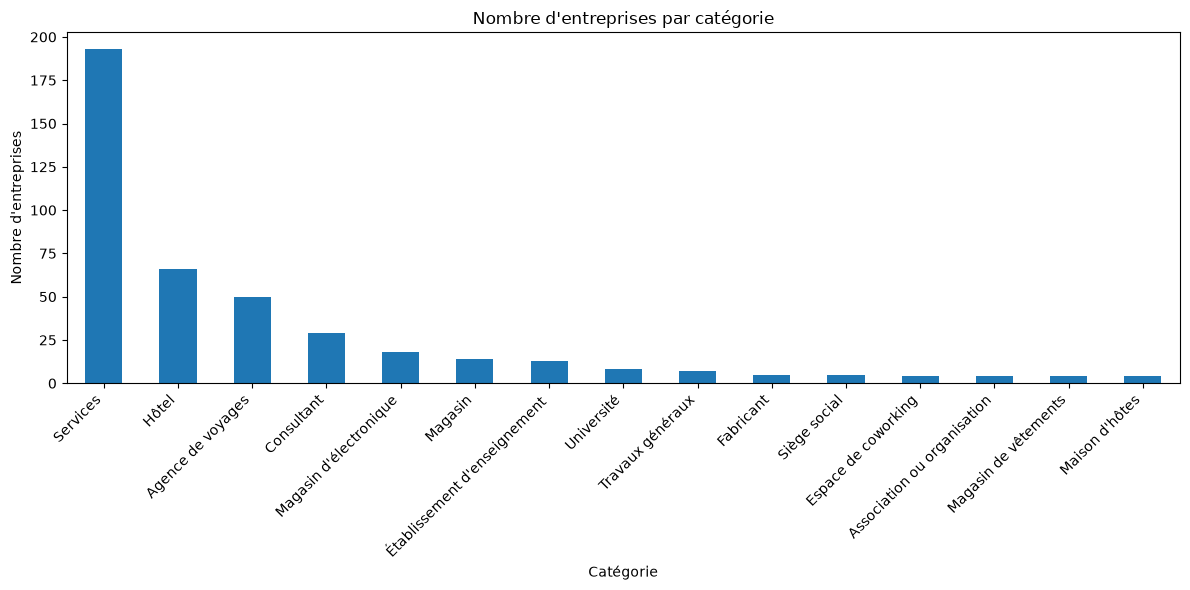

In [18]:
import matplotlib.pyplot as plt

category_counts = (
    df["categorie"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(12, 6))

category_counts.plot(
    kind="bar"
)

plt.title("Nombre d'entreprises par catégorie")
plt.xlabel("Catégorie")
plt.ylabel("Nombre d'entreprises")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.show()

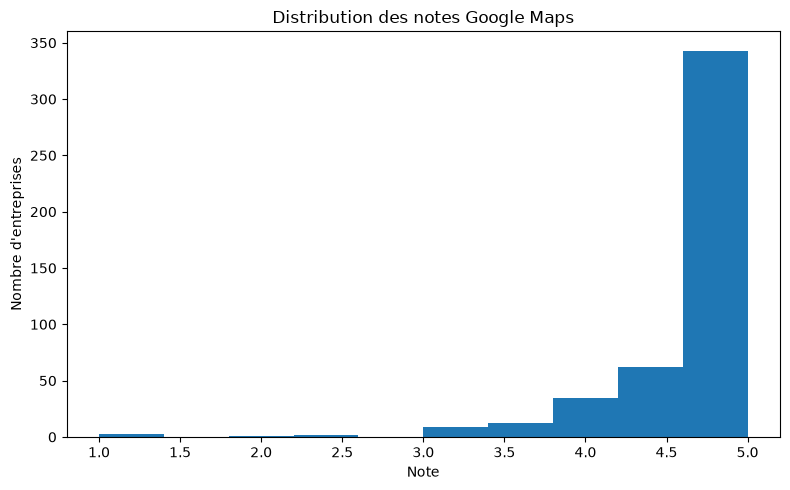

In [24]:
plt.figure(figsize=(8, 5))

df["note"].dropna().plot(
    kind="hist",
    bins=10
)

plt.title("Distribution des notes Google Maps")
plt.xlabel("Note")
plt.ylabel("Nombre d'entreprises")

plt.tight_layout()

plt.show()

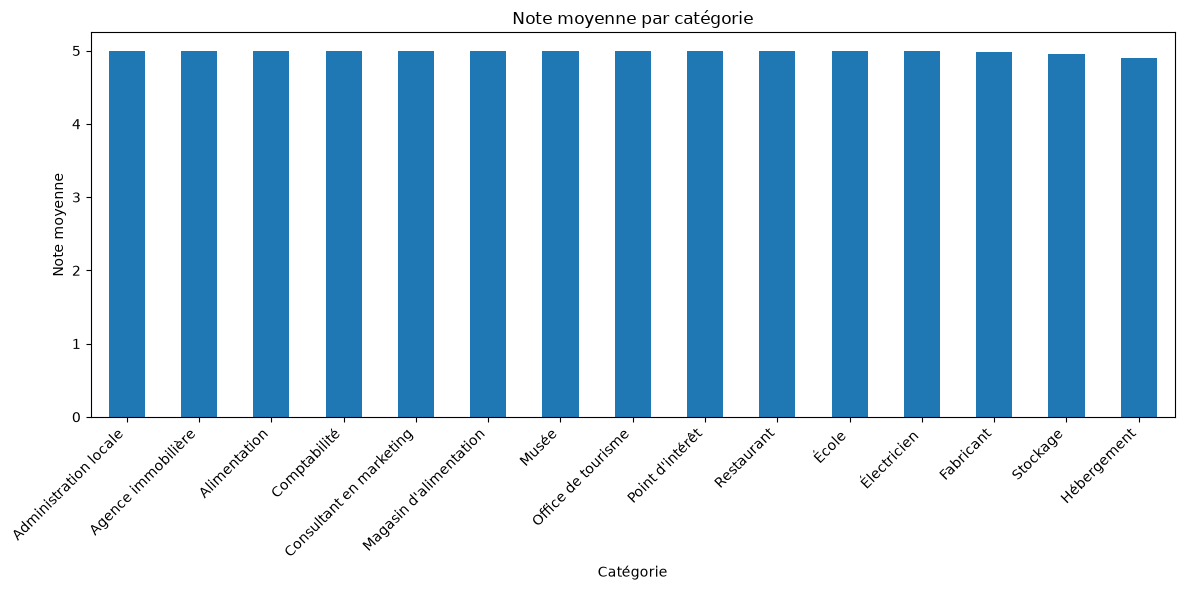

In [28]:
rating_by_category = (
    df.groupby("categorie")["note"]
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 6))

rating_by_category.plot(
    kind="bar"
)

plt.title(
    "Note moyenne par catégorie"
)

plt.xlabel("Catégorie")
plt.ylabel("Note moyenne")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.show()

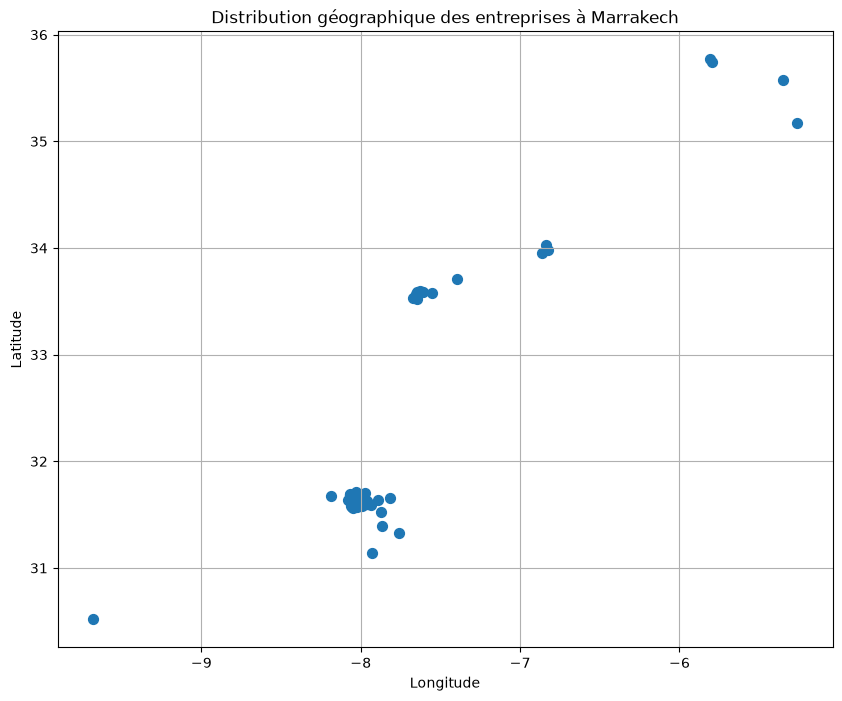

In [32]:
plt.figure(figsize=(10, 8))

plt.scatter(
    df["longitude"],
    df["latitude"],
    s=50
)

plt.title(
    "Distribution géographique des entreprises à Marrakech"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.grid(True)

plt.show()

pr

In [35]:
total_entreprises = df["nom"].nunique()

avg_rating = df["note"].mean()

total_reviews = df["nombre_avis"].sum()

categories = df["categorie"].nunique()

print("Total entreprises :", total_entreprises)
print("Note moyenne      :", round(avg_rating, 2))
print("Total avis        :", int(total_reviews))
print("Catégories        :", categories)

Total entreprises : 494
Note moyenne      : 4.67
Total avis        : 127858
Catégories        : 48


In [36]:
ranking = (
    df[
        ["nom", "note", "nombre_avis", "categorie"]
    ]
    .drop_duplicates("nom")
    .dropna(subset=["note"])
    .sort_values(
        ["note", "nombre_avis"],
        ascending=[False, False]
    )
    .head(15)
)

ranking

,nom,note,nombre_avis,categorie
123,Scenti,5.0,1920.0,Magasin de vêtements
405,Morocco Global Adventures,5.0,1919.0,Agence de voyages
402,Marrakech WITH Locals,5.0,888.0,Agence de voyages
117,Marrakech cooking class with locals,5.0,367.0,Alimentation
343,Artisanetshop : Wood Handicraft and Gifts shop,5.0,342.0,Boutique de cadeaux
489,Arabic Calligraphy workshops at THE HOUSE OF T...,5.0,288.0,NaN
16,La Cave à Huile - Huile d'Olive et d'Argan Pre...,5.0,279.0,Magasin d'alimentation
115,Maison culturelle du tapis,5.0,266.0,Musée
106,Globaloptical,5.0,236.0,Magasin
141,Morocco Inspiring Tours,5.0,234.0,Agence de voyages


In [38]:
import plotly.express as px

fig = px.bar(
    ranking.sort_values("note"),
    x="note",
    y="nom",
    orientation="h",
    text="note",
    title="Top entreprises selon la note"
)

fig.update_layout(
    template="plotly_white",
    height=600,
    xaxis_title="Note Google",
    yaxis_title="Entreprise"
)

fig.show()

In [39]:
category_counts = (
    df.groupby("categorie")["nom"]
    .nunique()
    .reset_index(name="entreprises")
    .sort_values("entreprises", ascending=False)
)

fig = px.bar(
    category_counts.head(15),
    x="entreprises",
    y="categorie",
    orientation="h",
    text="entreprises",
    title="Répartition des entreprises par catégorie"
)

fig.update_layout(
    template="plotly_white",
    height=600
)

fig.show()

In [40]:
scatter = (
    df[
        ["nom", "note", "nombre_avis", "categorie"]
    ]
    .drop_duplicates("nom")
    .dropna(subset=["note", "nombre_avis"])
)

fig = px.scatter(
    scatter,
    x="nombre_avis",
    y="note",
    size="nombre_avis",
    hover_name="nom",
    color="categorie",
    title="Note Google vs nombre d'avis",
    log_x=True
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Nombre d'avis",
    yaxis_title="Note Google"
)

fig.show()

In [45]:
from IPython.display import IFrame
import folium

# 1. Initialize the map using OpenStreetMap (No API key needed)
map_marrakech = folium.Map(
    location=[31.63, -8.00],
    zoom_start=12,
    tiles="OpenStreetMap"
)

# 2. Add circle markers for each location
for _, row in df.dropna(
    subset=["latitude", "longitude"]
).drop_duplicates("nom").iterrows():

    popup = f"""
    <b>{row['nom']}</b><br>
    Catégorie: {row['categorie']}<br>
    Note: {row['note']} ⭐<br>
    Avis: {row['nombre_avis']}<br>
    Adresse: {row['adresse']}
    """

    folium.CircleMarker(
        location=[
            row["latitude"],
            row["longitude"]
        ],
        radius=7,
        popup=folium.Popup(
            popup,
            max_width=350
        ),
        fill=True
    ).add_to(map_marrakech)

# 3. Save and display the map via IFrame
map_marrakech.save("map_marrakech.html")
IFrame(src="map_marrakech.html", width="100%", height=500)

In [50]:
query_stats = (
    df.groupby("query")["nom"]
    .nunique()
    .reset_index(name="entreprises")
    .sort_values(
        "entreprises",
        ascending=False
    )
)

import plotly.express as px

fig = px.bar(
    query_stats.head(20),
    x="entreprises",
    y="query",
    orientation="h",
    text="entreprises",
    title="Nombre d'entreprises par requête"
)

fig.update_layout(
    template="plotly_white",
    height=700,
    xaxis_title="Nombre d'entreprises",
    yaxis_title="Requête"
)

fig.show()

KeyError: 'query'